# CXC103

Includes Data Augmentation on training 

In [13]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)
from src.utils.ds_helper import get_dataset_distribution


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [14]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC1.keras"
model = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data03", "train")
test_data_dir = os.path.join(dataset_path, "data03", "test")
val_data_dir = os.path.join(dataset_path, "data03", "val")


# Set parameters
IMG_SIZE = (384, 384)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data03/train
/Users/joshan/Documents/final-year-project/dataset/data03/test
/Users/joshan/Documents/final-year-project/dataset/data03/val


In [15]:
get_dataset_distribution(
        [
          train_data_dir, 
          test_data_dir, 
          val_data_dir
        ]
    )

╒═══════════╤══════════╤═════════════╤════════════════╤═══════════╤═════════╕
│ Dataset   │   Normal │   Pneumonia │   Tuberculosis │   Unknown │   Total │
╞═══════════╪══════════╪═════════════╪════════════════╪═══════════╪═════════╡
│ Train     │     4667 │        3633 │           3573 │      1155 │   13028 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Test      │      548 │         427 │            417 │       135 │    1527 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Val       │      274 │         213 │            207 │        67 │     761 │
╘═══════════╧══════════╧═════════════╧════════════════╧═══════════╧═════════╛


{'train': {'NORMAL': 4667,
  'PNEUMONIA': 3633,
  'TUBERCULOSIS': 3573,
  'UNKNOWN': 1155},
 'test': {'NORMAL': 548,
  'PNEUMONIA': 427,
  'TUBERCULOSIS': 417,
  'UNKNOWN': 135},
 'val': {'NORMAL': 274, 'PNEUMONIA': 213, 'TUBERCULOSIS': 207, 'UNKNOWN': 67}}

In [16]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode='rgb',
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 13028 files belonging to 4 classes.
Found 1527 files belonging to 4 classes.
Found 761 files belonging to 4 classes.


In [5]:
class_names = train_ds.class_names

print("Class names:", class_names)

for i, label in enumerate(class_names):
    print(f"Index {i}: {label}")

Class names: ['NORMAL', 'PNEUMONIA', 'TUBERCULOSIS', 'UNKNOWN']
Index 0: NORMAL
Index 1: PNEUMONIA
Index 2: TUBERCULOSIS
Index 3: UNKNOWN


In [6]:
data_augmentation = models.Sequential([
    
    # Flip left-right (lungs are symmetric)
    layers.RandomFlip("horizontal"),
    
    # Small rotation for positioning differences
    layers.RandomRotation(0.05),
    
    # Slight zoom to simulate distance from scanner
    layers.RandomZoom(0.1),
    
    # Small translation for patient positioning
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    
    # Slight contrast variation from different scanners
    layers.RandomContrast(0.1),
    
])

In [7]:
model = models.Sequential([
    # Preprocessing: Rescale inputs to [0, 1]
    layers.Rescaling(1./255, input_shape=(384, 384, 3)),
    
    # First convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Second convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Third convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and Classify
    layers.Flatten(),
    layers.Dense(128, activation='relu'),  
    layers.Dropout(0.5), # Helps prevent overfitting by dropping out 0.5 acc 
    layers.Dense(4, activation='softmax') # Softmax for multi-class probability
])

/Users/joshan/Documents/final-year-project/backend/.venv/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [8]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Epoch 1/10


2026-04-04 13:36:29.797621: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


408/408 ━━━━━━━━━━━━━━━━━━━━ 142s 339ms/step - accuracy: 0.7009 - loss: 1.5652 - val_accuracy: 0.8594 - val_loss: 0.6392
Epoch 2/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 138s 336ms/step - accuracy: 0.7403 - loss: 3.7890 - val_accuracy: 0.8042 - val_loss: 1.1054
Epoch 3/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 137s 335ms/step - accuracy: 0.7792 - loss: 1.8347 - val_accuracy: 0.8844 - val_loss: 0.8472
Epoch 4/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 138s 338ms/step - accuracy: 0.8094 - loss: 1.2900 - val_accuracy: 0.8660 - val_loss: 0.9170
Epoch 5/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 137s 335ms/step - accuracy: 0.8223 - loss: 1.6033 - val_accuracy: 0.6754 - val_loss: 2.9236
Epoch 6/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 137s 335ms/step - accuracy: 0.8288 - loss: 1.8880 - val_accuracy: 0.8410 - val_loss: 2.0740
Epoch 7/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 135s 330ms/step - accuracy: 0.8386 - loss: 2.1971 - val_accuracy: 0.9198 - val_loss: 0.8645
Epoch 8/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 138s 337ms/step - accuracy: 0.8585 - loss: 2.17

In [9]:
# Save the model
model.save('CXC103.keras')
print("Model saved successfully!")

Model saved successfully!


In [10]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - accuracy: 0.7754 - loss: 12.4888
Test Loss: 12.48878288269043
Test Accuracy: 77.54%


2026-04-04 13:59:34.325466: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


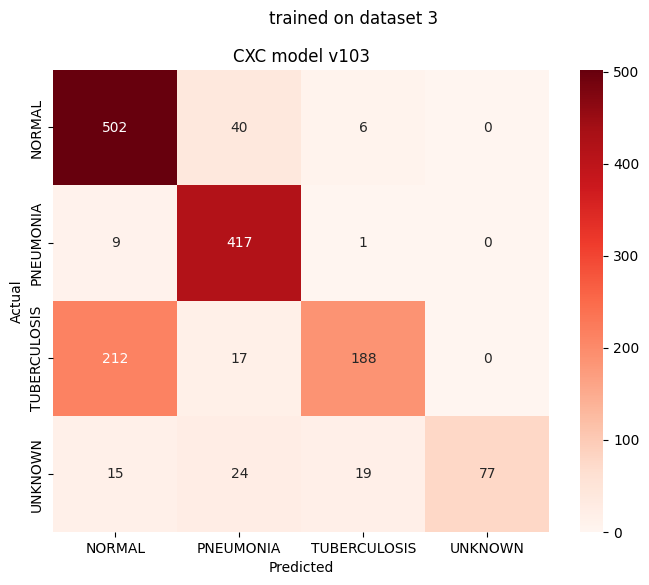

              precision    recall  f1-score   support

      NORMAL       0.68      0.92      0.78       548
   PNEUMONIA       0.84      0.98      0.90       427
TUBERCULOSIS       0.88      0.45      0.60       417
     UNKNOWN       1.00      0.57      0.73       135

    accuracy                           0.78      1527
   macro avg       0.85      0.73      0.75      1527
weighted avg       0.81      0.78      0.76      1527



In [11]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CXC model v103')
plt.suptitle("trained on dataset 3")
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))

In [12]:
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - accuracy: 0.7832 - loss: 13.9375
Test Loss: 13.93752670288086
Test Accuracy: 78.32%
